# Part 1 - Interpret the Edge-List Data

1. One row represents what one employee rated the other on a scale from 1-3

2. The rating is considered an edge attribute because the rating will be the weight of the edge.

3. Employee A gave Employee B a rating of 3.

4. Converting this network to an undirected graph would cause the ratings to not mean what they orginally meant. The meaning of the rating will be lost because we won't be able to see who rated who but rather just a weight on the edge.


# Part 2 - Read the CSV File

In [47]:
from google.colab import files
uploaded = files.upload()

Saving rate.csv to rate (1).csv


In [48]:
import pandas as pd

df = pd.read_csv("rate.csv")


df.head()

,From,To,Rate
0,ROMUL,AMBROSE,2
1,ROMUL,PETER,3
2,ROMUL,ALBERT,1
3,BONAVEN,ROMUL,3
4,BONAVEN,VICTOR,2


In [49]:
# to get amount of rows
df.shape

(55, 3)

1. There are 55 rows in the dataset

2. The three columns are From, To, and Rate.

3. Yes, the number of rows agrees with the problem description.

4. Yes, because we have the two entities and their relationship stored as columns that can be easily made into a graph

# Part 3 - Create the Directed Network

In [50]:
import networkx as nx
import matplotlib.pyplot as plt


dg = nx.from_pandas_edgelist(df, source="From", target="To", edge_attr="Rate", create_using=nx.DiGraph())

# Part 4 - Verify the Graph

In [51]:
print(dg.number_of_nodes())

print(dg.number_of_edges())

list(dg.edges())[0]

18
55


('ROMUL', 'AMBROSE')

1. There are 18 nodes
2. There are 55 edges
3. Yes, this does match the problem description which states that there are 18 employees (nodes) and 55 ratings (55 edges)
4. The edge between 'ROMUL' and 'AMBROSE' means that ROMUL gave AMBROSE a rating.

# Part 5 - Visualize the Network

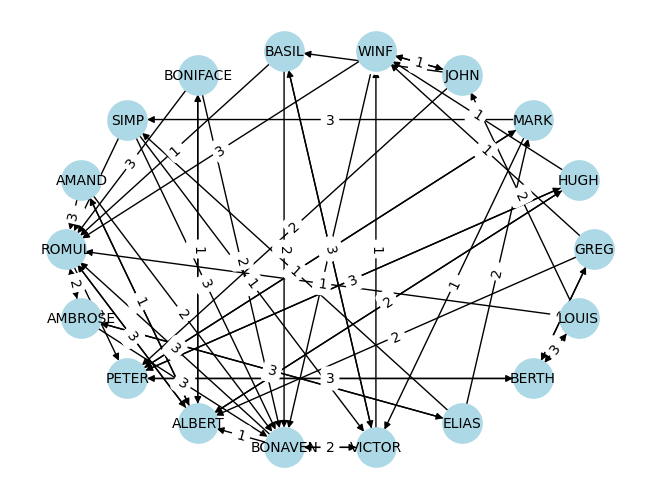

In [52]:
pos = nx.shell_layout(dg)

nx.draw(dg, pos, with_labels=True, node_color='lightblue', node_size=800, font_size=10)

# gets edge weights
edge_labels = nx.get_edge_attributes(dg, 'Rate')
nx.draw_networkx_edge_labels(dg, pos, edge_labels=edge_labels)

plt.show()

1. The first observation I can make is that there are some nodes that have a higher degree than others which means that some employees got more ratings about them than others. The second observation is that the length of a walk for each node is the same since each node only has one edge between them and another node.

2. Something that would be difficult to determine only by looking at the visualization is why some employees have more ratings than others.

# Part 6 - Analyze Indegree and Outdegree

In [53]:
dg.in_degree()

InDegreeView({'ROMUL': 9, 'AMBROSE': 2, 'PETER': 5, 'ALBERT': 6, 'BONAVEN': 7, 'VICTOR': 4, 'ELIAS': 1, 'BERTH': 3, 'LOUIS': 1, 'GREG': 1, 'HUGH': 2, 'MARK': 2, 'JOHN': 2, 'WINF': 4, 'BASIL': 2, 'BONIFACE': 1, 'SIMP': 2, 'AMAND': 1})

In [54]:
dg.out_degree()

OutDegreeView({'ROMUL': 3, 'AMBROSE': 3, 'PETER': 3, 'ALBERT': 4, 'BONAVEN': 3, 'VICTOR': 3, 'ELIAS': 3, 'BERTH': 3, 'LOUIS': 3, 'GREG': 3, 'HUGH': 3, 'MARK': 3, 'JOHN': 3, 'WINF': 3, 'BASIL': 3, 'BONIFACE': 3, 'SIMP': 3, 'AMAND': 3})

## Question 1
Which employee was rated by the largest number of other employees?

**Answer**: Romul has an indegree of 9 which means that 9 other employees gave Romul a rating

## Question 2
Which employee rated the largest number of employees?

**Answer**: Albert has an outdegree of 4 which means that they gave 4 ratings to other employees.

## Question 3
Are these the same employee?

**Answer**: No, these are the not the same employees because indegree refers to the number of edges directed into a node. The edges represent the rating and node represents an employee, so by this definition, Romul had 9 ratings about them. An outdegree refers the number of edges directed out of a node. If we are going by the previous definition then this means Albert gave 4 ratings to 4 other employees.


# Part 7 - Analyze the Ratings

In [55]:
# highest avg rating = Berth
# lowest avg rating = Louis

df.groupby('To')['Rate'].mean().sort_values(ascending=False)


,Rate
To,
BERTH,3.000000
PETER,2.600000
AMBROSE,2.500000
ROMUL,2.333333
BONAVEN,2.285714
AMAND,2.000000
SIMP,2.000000
GREG,2.000000
BONIFACE,2.000000


1. Berth received the highest average rating. They had an average rating of 3.0 with 3 ratings given to them.
2. Louis received the lowest average rating of 1.0 with 1 rating given to them.

## Interpretation
The number of ratings should be considered when interpreting the average because a lower number or a single rating does not tell the full story or even a reasonable part of the story. An average rating of 2.9 from ten people gives a bigger sample size which provides a more accurate representation of the employee than a single 1.0 rating.

# Part 8 - Additional Observations

In [56]:
# employees who rated other employees

df.groupby('From')['Rate'].count()


,Rate
From,
ALBERT,4
AMAND,3
AMBROSE,3
BASIL,3
BERTH,3
BONAVEN,3
BONIFACE,3
ELIAS,3
GREG,3


# Observation 1
1. I found that mostly everyone gave three ratings except for one employee, Albert, who gave 4 ratings.
2. The evidence is in the Pandas series above.
3. This means that everyone was able to vote at least 3 times

In [57]:
# comparison between the three employees who received the most ratings

# romul has 9 ratings, bonaven 7, albert 6
df.groupby('To')['Rate'].count().sort_values(ascending=False)

emp_list = ['ROMUL', 'BONAVEN', 'ALBERT']
rate_list = []

for emp in emp_list:
  avg_rate = df[df['To'] == emp]['Rate'].mean()
  rate_list.append(avg_rate)

rate_list


[np.float64(2.3333333333333335),
 np.float64(2.2857142857142856),
 np.float64(1.3333333333333333)]

# Observation 2
1. I found that Romul has an average rating of 2.33, Bonaven has an average rating of 2.29, and Albert has an average rating of 1.33. Albert has 6 ratings but still has a low score while the other two are in the average range.

2. Evidence is in the Pandas statement above.

3. This means that Albert has a low score even though he was given many reviews (6) and that the other two employees with the most reviews had an average rating that was slightly above the average of 2.

# Part 9 - AI-Assisted Learning

## AI Use
1. "In networkx how can i draw the weight of the edges and names of the nodes."

2. The AI showed me example code that showed me example code that used parameters and methods that allowed me to draw the weights of the edges and the names of the nodes. Some of these parameters included with_labels, node_color, node_size, and font_size. To draw the labels for the edges, the AI showed me "nx.get_edge_attributes()" that helped me get the attributes (rating) and "nx.draw_networkx_edge_labels()" which helped me label that attribute to the edge.

3. I checked that the suggestion was correct using the docs and a youtube video showcasing similar code to display the information that I wanted to display.

4. I modified the suggestion slightly since I had a specific attribute (Rate) and had different specifications for color and font size.

# Part 10 - Reflection

This assignment showed me the intersection between using Pandas, which I have previous experience with, and using Networkx. I was able to see the areas in which I can use the graph to help me interpret results and use Pandas to help. For example, finding out the average rating for a particular employee is easier in Pandas but getting an overall idea of the relationships in the data is a lot easier with a graph representation fo the data.